# Spotify Track Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Data Loading

In [2]:
# Loading data
df = pd.read_csv("../../data/raw/spotify_2014_2020_dataset.csv")

## Exploration

In [3]:
# Sample Rows (First 5)
df.head()

,Track_ID,Track_Name,Duration_Min,Artists,Release_Date,Year,Query
0,6dBUzqjtbnIa1TwYbyw5CM,Lovers Rock,3.57,TV Girl,6/5/2014,2014,love
1,5J4ZkQpzMUFojo1CtAZYpn,Love Me Harder,3.94,"Ariana Grande, The Weeknd",8/22/2014,2014,love
2,2e3Ea0o24lReQFR4FA7yXH,Love Yourz,3.52,J. Cole,12/9/2014,2014,love
3,6nGeLlakfzlBcFdZXteDq7,Love Story,5.27,Indila,1/1/2014,2014,love
4,5BJSZocnCeSNeYMj3iVqM7,Love Runs Out,3.74,OneRepublic,1/1/2014,2014,love


In [4]:
# data types + missing values
df.info()

# stats (mean, std, etc.)
data_decription = df.describe()
print("\nDescription of data:\n", data_decription)

<class 'pandas.DataFrame'>
RangeIndex: 1701 entries, 0 to 1700
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Track_ID      1701 non-null   str    
 1   Track_Name    1701 non-null   str    
 2   Duration_Min  1701 non-null   float64
 3   Artists       1701 non-null   str    
 4   Release_Date  1701 non-null   str    
 5   Year          1701 non-null   int64  
 6   Query         1701 non-null   str    
dtypes: float64(1), int64(1), str(5)
memory usage: 93.2 KB

Description of data:
        Duration_Min         Year
count   1701.000000  1701.000000
mean       4.268595  2016.513815
std        5.260055     1.854553
min        3.000000  2014.000000
25%        3.460000  2015.000000
50%        3.830000  2016.000000
75%        4.320000  2018.000000
max      180.470000  2020.000000


In [5]:
cols = df.columns
print("All columns:\n", cols)

All columns:
 Index(['Track_ID', 'Track_Name', 'Duration_Min', 'Artists', 'Release_Date',
       'Year', 'Query'],
      dtype='str')


## Data Quality Check

Checking for null in the data

In [6]:
# Checking for issues - finding the total of isNull
df.isnull().sum()

# if there is null then use: df = df.dropna()  # or fillna()

Track_ID        0
Track_Name      0
Duration_Min    0
Artists         0
Release_Date    0
Year            0
Query           0
dtype: int64

## Date Parsing

Converting `Release_Date` to datetime, extracting `Month` and `Day`

In [7]:
# conversion of dates
df['Release_Date'] = pd.to_datetime(df['Release_Date'], format='mixed')
df['Month'] = df['Release_Date'].dt.month
df['Day'] = df['Release_Date'].dt.day

## Data Reshaping

Exploding multi-artist strings into one artist per row

In [8]:
# Handling Artists
df['Artists'] = df['Artists'].str.split(', ')

# Each row = one artist per song
df_exploded = df.explode('Artists')

df_exploded.head()

,Track_ID,Track_Name,Duration_Min,Artists,Release_Date,Year,Query,Month,Day
0,6dBUzqjtbnIa1TwYbyw5CM,Lovers Rock,3.57,TV Girl,2014-06-05,2014,love,6,5
1,5J4ZkQpzMUFojo1CtAZYpn,Love Me Harder,3.94,Ariana Grande,2014-08-22,2014,love,8,22
1,5J4ZkQpzMUFojo1CtAZYpn,Love Me Harder,3.94,The Weeknd,2014-08-22,2014,love,8,22
2,2e3Ea0o24lReQFR4FA7yXH,Love Yourz,3.52,J. Cole,2014-12-09,2014,love,12,9
3,6nGeLlakfzlBcFdZXteDq7,Love Story,5.27,Indila,2014-01-01,2014,love,1,1


In [9]:
df_exploded.head(20)

,Track_ID,Track_Name,Duration_Min,Artists,Release_Date,Year,Query,Month,Day
0,6dBUzqjtbnIa1TwYbyw5CM,Lovers Rock,3.57,TV Girl,2014-06-05,2014,love,6,5
1,5J4ZkQpzMUFojo1CtAZYpn,Love Me Harder,3.94,Ariana Grande,2014-08-22,2014,love,8,22
1,5J4ZkQpzMUFojo1CtAZYpn,Love Me Harder,3.94,The Weeknd,2014-08-22,2014,love,8,22
2,2e3Ea0o24lReQFR4FA7yXH,Love Yourz,3.52,J. Cole,2014-12-09,2014,love,12,9
3,6nGeLlakfzlBcFdZXteDq7,Love Story,5.27,Indila,2014-01-01,2014,love,1,1
4,5BJSZocnCeSNeYMj3iVqM7,Love Runs Out,3.74,OneRepublic,2014-01-01,2014,love,1,1
5,48td6xvpokdYwvbl3JIiXP,Love Never Felt So Good,4.11,Michael Jackson,2014-05-09,2014,love,5,9
5,48td6xvpokdYwvbl3JIiXP,Love Never Felt So Good,4.11,Justin Timberlake,2014-05-09,2014,love,5,9
6,3sslYZcFKtUvIEWN9lADgr,First Love/Late Spring,4.64,Mitski,2014-11-11,2014,love,11,11
7,7jXaTTqkOupMhGhQdyXDTN,Love Somebody (feat. Young Thug),3.54,Gucci Mane,2014-05-26,2014,love,5,26


In [10]:
data = df_exploded.iloc[:, 1:].reset_index(drop=True)
data

,Track_Name,Duration_Min,Artists,Release_Date,Year,Query,Month,Day
0,Lovers Rock,3.57,TV Girl,2014-06-05,2014,love,6,5
1,Love Me Harder,3.94,Ariana Grande,2014-08-22,2014,love,8,22
2,Love Me Harder,3.94,The Weeknd,2014-08-22,2014,love,8,22
3,Love Yourz,3.52,J. Cole,2014-12-09,2014,love,12,9
4,Love Story,5.27,Indila,2014-01-01,2014,love,1,1
...,...,...,...,...,...,...,...,...
2707,Sudden Desire,3.13,Hayley Williams,2020-05-08,2020,sad,5,8
2708,Brown Sleep Noise,4.13,Sleep Miracle,2020-12-16,2020,sad,12,16
2709,SAD GIRLZ LUV MONEY,3.27,Amaarae,2020-11-12,2020,sad,11,12
2710,SAD GIRLZ LUV MONEY,3.27,MOLIY,2020-11-12,2020,sad,11,12


## Analysis and Visualization

In [11]:
# Top artists
data['Artists'].value_counts().head(10)

Artists
Anuel AA             21
Lil Peep             21
Farruko              19
Ozuna                19
Bad Bunny            19
Twenty One Pilots    17
A$AP Rocky           17
The Weeknd           15
Nicki Minaj          15
Post Malone          15
Name: count, dtype: int64

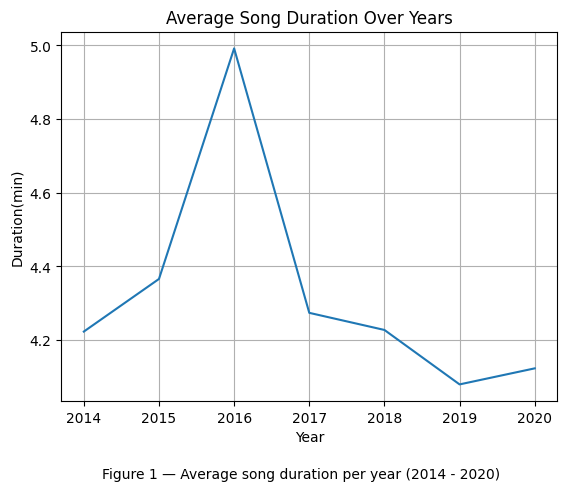

In [12]:
# Average duration by year
data.groupby('Year')['Duration_Min'].mean().plot()

# Plot
plt.title("Average Song Duration Over Years")
plt.xlabel("Year")
plt.ylabel("Duration(min)")
plt.grid(True)

# Caption
plt.figtext(
    0.5, -0.05,
    "Figure 1 — Average song duration per year (2014 - 2020)",
    ha="center",
    fontsize=10
)

# Save
plt.savefig("../../outputs/figures/spotify/avg_duration_by_year.png", dpi=300, bbox_inches='tight')

# Display
plt.show()

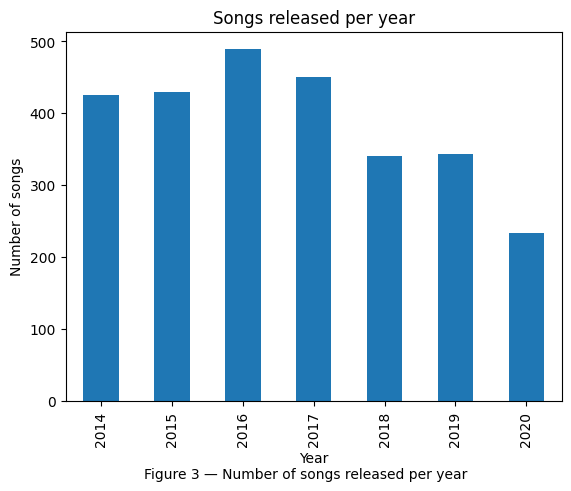

In [13]:
# Songs released per year
data['Year'].value_counts().sort_index().plot(kind='bar')

# Plot
plt.title("Songs released per year")
plt.xlabel("Year")
plt.ylabel("Number of songs")

# Caption
plt.figtext(
    0.5, -0.05,
    "Figure 3 — Number of songs released per year",
    ha="center",
    fontsize=10
)

# Save
plt.savefig("../../outputs/figures/spotify/songs_released_per_year.png", dpi=300, bbox_inches='tight')

# Display
plt.show()

### Distribution Analysis

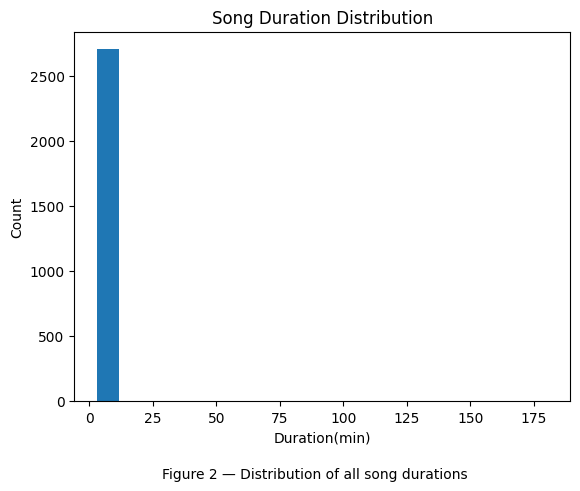

In [14]:
# Duration spread
plt.hist(data['Duration_Min'], bins=20)

# Plot
plt.title("Song Duration Distribution")
plt.xlabel("Duration(min)")
plt.ylabel("Count")

# Caption
plt.figtext(
    0.5, -0.05,
    "Figure 2 — Distribution of all song durations",
    ha="center",
    fontsize=10
)

# Save
plt.savefig("../../outputs/figures/spotify/song_duration_distribution_spread.png", dpi=300, bbox_inches='tight')

# Display
plt.show()

In [15]:
# Query category with longest and shortest songs on average
avg_dur = data.groupby('Query')['Duration_Min'].mean()

# Find the Query with the maximum average duration
longest_avg_query = avg_dur.idxmax()
longest_avg_dur = avg_dur.max()

print("Query with longest songs on average:", longest_avg_query)
print("Average duration (minutes):", np.round(longest_avg_dur, 2))

# Find the Query with the minimum average duration
shortest_avg_query = avg_dur.idxmin()
shortest_avg_dur = avg_dur.min()

print("\nQuery with shortest songs on average:", shortest_avg_query)
print("Average duration (minutes):", np.round(shortest_avg_dur, 2))

Query with longest songs on average: sad
Average duration (minutes): 4.67

Query with shortest songs on average: love
Average duration (minutes): 3.86


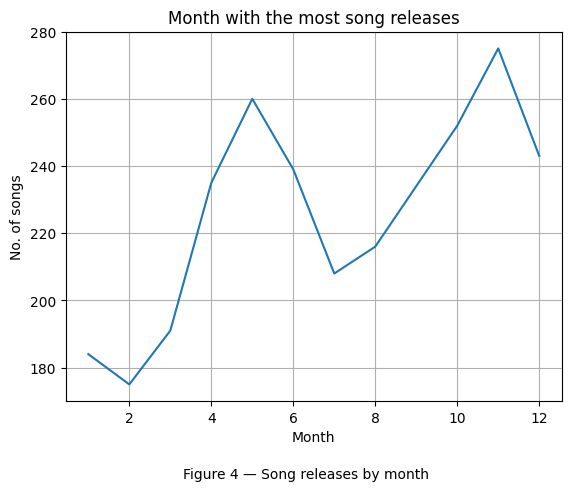

In [16]:
# month with the most song releases
data['Month'].value_counts().sort_index().plot(kind='line')

# Plot
plt.title("Month with the most song releases")
plt.xlabel("Month")
plt.ylabel("No. of songs")
plt.grid(True)

# Caption
plt.figtext(
    0.5, -0.05,
    "Figure 4 — Song releases by month",
    ha="center",
    fontsize=10
)

# Save
plt.savefig("../../outputs/figures/spotify/month_song.png", dpi=300, bbox_inches='tight')

# Display
plt.show()

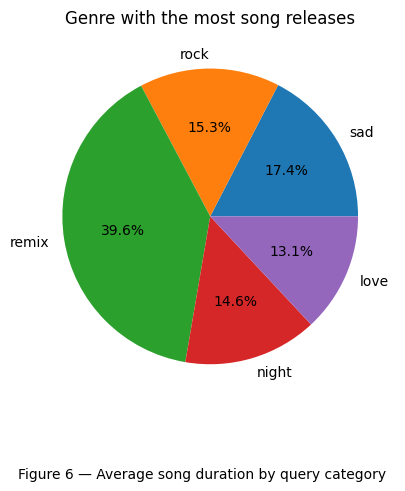

In [17]:
# genre with the most song releases
data['Query'].value_counts().sort_index(ascending=False).plot( kind='pie', autopct='%1.1f%%', legend=False )
plt.title('Genre with the most song releases')

# Caption
plt.figtext(
    0.5, -0.05,
    "Figure 6 — Average song duration by query category",
    ha="center",
    fontsize=10
)

# Save
plt.savefig("../../outputs/figures/spotify/genre_percent.png", dpi=300, bbox_inches='tight')

# Display
plt.show()

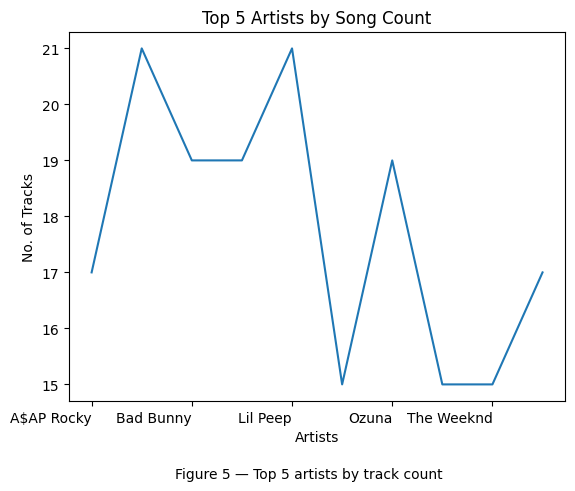

In [18]:
# Artist
data['Artists'].value_counts().head(10).sort_index().plot(kind='line')

# Plot
plt.title('Top 5 Artists by Song Count')
plt.xlabel("Artists")
plt.ylabel("No. of Tracks")
plt.xticks(rotation=0, ha='right')

# Caption
plt.figtext(
    0.5, -0.05,
    "Figure 5 — Top 5 artists by track count",
    ha="center",
    fontsize=10
)

# Save
plt.savefig("../../outputs/figures/spotify/artist_song_count.png", dpi=300, bbox_inches='tight')

# Display
plt.show()

In [19]:
# %age of songs are collaborations (multiple artists)

# Count number of artists per song
artist_counts = data.groupby(['Track_Name', 'Release_Date'])['Artists'].nunique()

# Identify collaborations (>1 artist)
is_collab = artist_counts > 1

# Get percentage
collab_percentage = (is_collab.sum() / len(is_collab)) * 100

print("Collab %age: ", np.round(collab_percentage, 2))

Collab %age:  33.41


In [20]:
# Top artists per year — is the same artist dominating multiple years?

# Count songs per artist per year
artist_year_count = data.groupby(['Year', 'Artists']).size().reset_index(name='song_count')
max_counts = artist_year_count.groupby('Year')['song_count'].transform('max')

# Get top artist for each year
top_artists_per_year = artist_year_count[
    artist_year_count['song_count'] == max_counts
].sort_values('Year')

print(top_artists_per_year)

      Year            Artists  song_count
161   2014       Milky Chance          12
561   2015        Tame Impala          10
586   2015  Twenty One Pilots          10
792   2016           Lil Peep          11
970   2017         A$AP Rocky           9
1397  2018         Juice WRLD           7
1753  2019       Taylor Swift           8
1912  2020        Myke Towers           5
1933  2020     Rauw Alejandro           5
